In [1]:
import pandas as pd
df = pd.read_csv("../data/iris.csv")

In [2]:
df.head()

,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


In [3]:
df.shape

(150, 5)

In [4]:
df.columns

Index(['sepal_length', 'sepal_width', 'petal_length', 'petal_width',
       'species'],
      dtype='str')

In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   sepal_length  150 non-null    float64
 1   sepal_width   150 non-null    float64
 2   petal_length  150 non-null    float64
 3   petal_width   150 non-null    float64
 4   species       150 non-null    str    
dtypes: float64(4), str(1)
memory usage: 6.0 KB


In [6]:
df.isnull().sum()

sepal_length    0
sepal_width     0
petal_length    0
petal_width     0
species         0
dtype: int64

In [7]:
df.duplicated().sum()

np.int64(1)

In [8]:
df.describe()

,sepal_length,sepal_width,petal_length,petal_width
count,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.057333,3.758000,1.199333
std,0.828066,0.435866,1.765298,0.762238
min,4.300000,2.000000,1.000000,0.100000
25%,5.100000,2.800000,1.600000,0.300000
50%,5.800000,3.000000,4.350000,1.300000
75%,6.400000,3.300000,5.100000,1.800000
max,7.900000,4.400000,6.900000,2.500000


In [9]:
X = df.drop(columns=["species"])

y = df["species"]

In [10]:
print("Feature shape: ", X.shape)
print("Target shape: ", y.shape)

print("Feature names: ", X.columns.tolist())
print("Target names: ", y.unique())

Feature shape:  (150, 4)
Target shape:  (150,)
Feature names:  ['sepal_length', 'sepal_width', 'petal_length', 'petal_width']
Target names:  <StringArray>
['setosa', 'versicolor', 'virginica']
Length: 3, dtype: str


In [11]:
y.value_counts()

species
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64

In [12]:
y.value_counts(normalize=True)

species
setosa        0.333333
versicolor    0.333333
virginica     0.333333
Name: proportion, dtype: float64

# Exploratory Data Analysis(EDA)

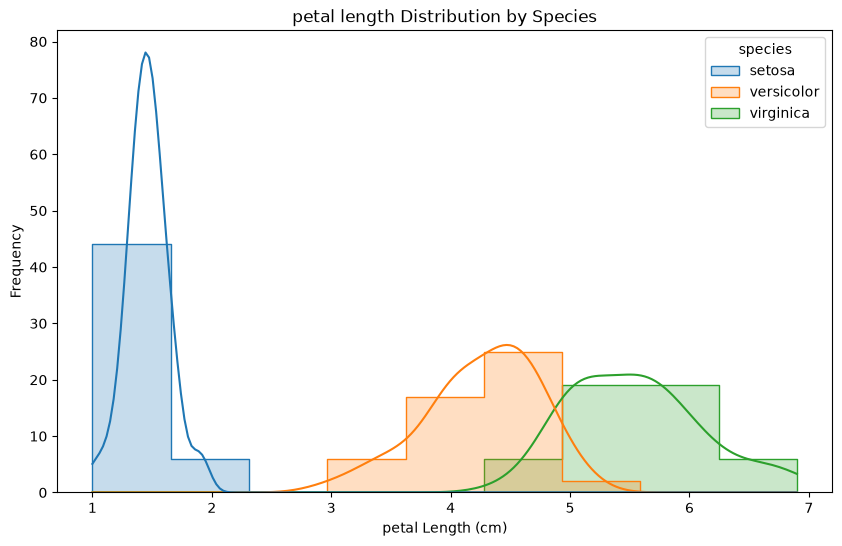

In [13]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10,6))
sns.histplot(
    data=df,
    x="petal_length",
    hue="species",
    kde=True,
    element="step",
)
plt.title("petal length Distribution by Species")
plt.xlabel("petal Length (cm)")
plt.ylabel("Frequency")

plt.show()

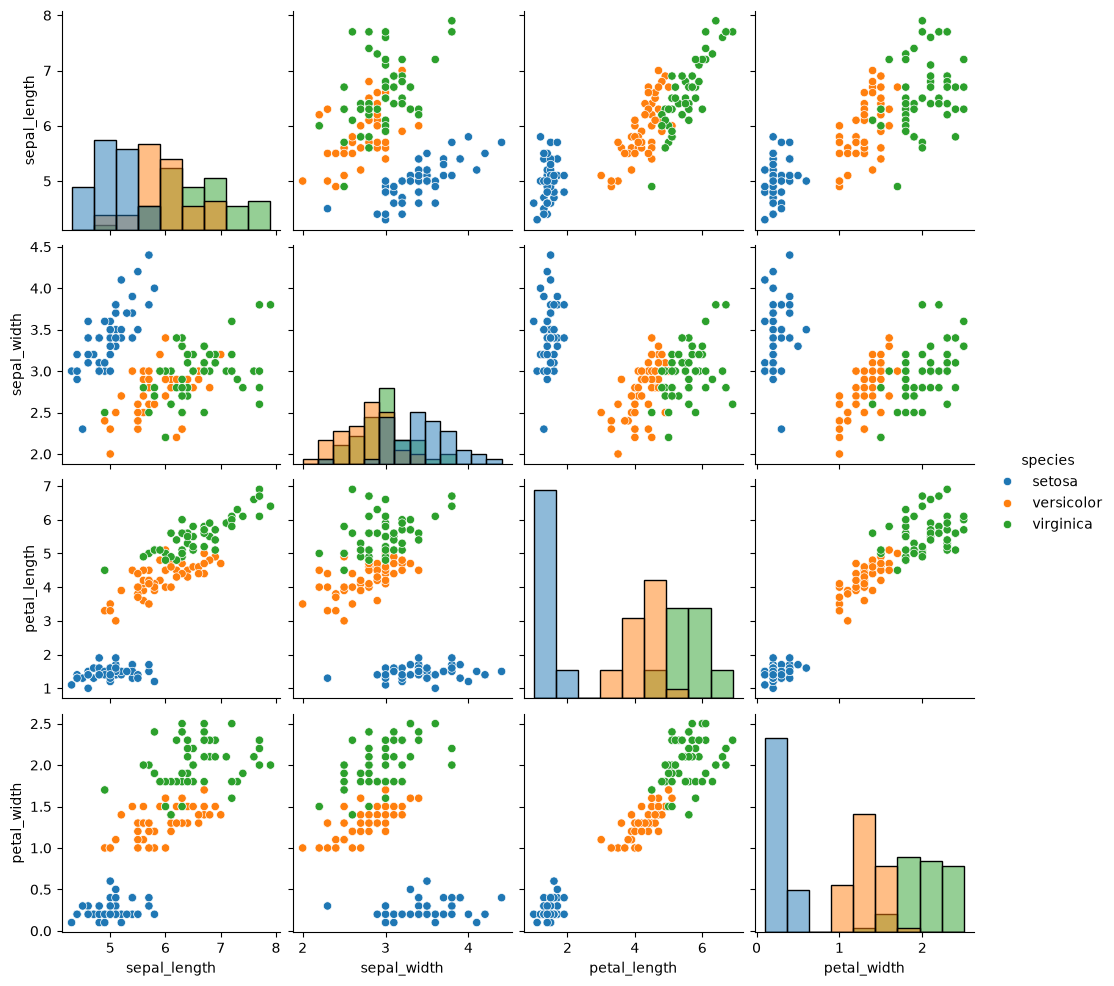

In [18]:
sns.pairplot(
    df,
    hue="species",
    diag_kind="hist"
)

plt.show()

Pairplot Observation
The pairplot shows clear clustering of the three iris species. Setosa forms a distinct cluster and is easily separable from the other species. Petal length and petal width provide the strongest separation between classes, while sepal measurements show greater overlap. Versicolor and Virginica exhibit some overlap but remain largely distinguishable. These observations suggest that the dataset is well suited for classification tasks.

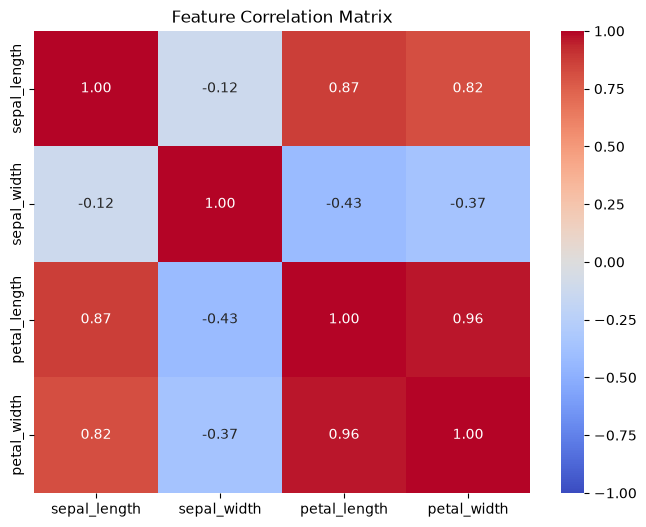

In [15]:
correlation_matrix = X.corr()

plt.figure(figsize=(8, 6))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    vmin=-1,
    vmax=1
)

plt.title("Feature Correlation Matrix")

plt.show()

# Correlation Matrix asks:

"How strongly are the features related to each other?"

For example:

 
If petal_length increases,

does petal_width also increase?

Correlation goes from:

 
-1 → Perfect negative relationship

0 → No relationship

+1 → Perfect positive relationship

# as preview
1, petal_length ↔ petal_width = 0.96
means like "Flowers with longer petals usually aslo have wider petals  so it has strong positive Relationship

2, sepal_length ↔ petal_length = 0.87
means like "Flowers with longer sepals tend to have longer petals
so it has also positive and very strong relationship

3, sepal_width ↔ petal_length = -0.43
means like As petal length invrease sepal width tends to decrease somewhat and negative correlation also like Not a perfect relationship, but there is a tendency

4, sepal_length ↔ sepal_width = -0.12
means like almost no linear relationship
knowing sepal length doesn't tell us much about sepal width , very close to zero

# Prepare Data for Machine Learning

In [20]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [21]:
print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("\n Training labels:")
print(y_train.value_counts())

print("\n Testing labels:")
print(y_test.value_counts())

Training features: (120, 4)
Testing features: (30, 4)

 Training labels:
species
setosa        40
virginica     40
versicolor    40
Name: count, dtype: int64

 Testing labels:
species
setosa        10
virginica     10
versicolor    10
Name: count, dtype: int64


In [ ]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

Logistic_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(max_iter=1000))
])
logistic_pipeline.fit(X_train, y_train)
